In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [2]:
df=pd.read_csv("data.csv",encoding="latin1")
df

,Duration,Date,Pulse,Maxpulse,Calories
0,60,'2020/12/01',110,130,409.1
1,60,'2020/12/02',117,145,479.0
2,60,'2020/12/03',103,135,340.0
3,45,'2020/12/04',109,175,282.4
4,45,'2020/12/05',117,148,406.0
5,60,'2020/12/06',102,127,300.0
6,60,'2020/12/07',110,136,374.0
7,450,'2020/12/08',104,134,253.3
8,30,'2020/12/09',109,133,195.1
9,60,'2020/12/10',98,124,269.0


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32 entries, 0 to 31
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Duration  32 non-null     int64  
 1   Date      31 non-null     object 
 2   Pulse     32 non-null     int64  
 3   Maxpulse  32 non-null     int64  
 4   Calories  30 non-null     float64
dtypes: float64(1), int64(3), object(1)
memory usage: 1.4+ KB


In [4]:
df.isnull().sum()

,0
Duration,0
Date,1
Pulse,0
Maxpulse,0
Calories,2


In [5]:
df.duplicated().sum()

np.int64(1)

In [6]:
df.drop_duplicates(inplace=True)

In [7]:
df["Calories"].describe()

,Calories
count,29.000000
mean,306.541379
std,66.365909
min,195.100000
25%,250.700000
50%,300.000000
75%,345.300000
max,479.000000


In [8]:
df["Calories"]=df["Calories"].fillna(df["Calories"].mean())

In [10]:
df["Date"]=pd.to_datetime(df["Date"],format="mixed",errors="coerce")
df

,Duration,Date,Pulse,Maxpulse,Calories
0,60,2020-12-01,110,130,409.100000
1,60,2020-12-02,117,145,479.000000
2,60,2020-12-03,103,135,340.000000
3,45,2020-12-04,109,175,282.400000
4,45,2020-12-05,117,148,406.000000
5,60,2020-12-06,102,127,300.000000
6,60,2020-12-07,110,136,374.000000
7,450,2020-12-08,104,134,253.300000
8,30,2020-12-09,109,133,195.100000
9,60,2020-12-10,98,124,269.000000


In [15]:
more_than_30=df[df["Duration"]>100]
more_than_30

,Duration,Date,Pulse,Maxpulse,Calories
7,450,2020-12-08,104,134,253.3


In [16]:
cals_less_than_200=df[df["Calories"]<200]
cals_less_than_200

,Duration,Date,Pulse,Maxpulse,Calories
8,30,2020-12-09,109,133,195.1


In [18]:
df["Workout_Type"]=np.where(df["Duration"]>60 ,"Long","Short")
df

,Duration,Date,Pulse,Maxpulse,Calories,Workout_Type
0,60,2020-12-01,110,130,409.100000,Short
1,60,2020-12-02,117,145,479.000000,Short
2,60,2020-12-03,103,135,340.000000,Short
3,45,2020-12-04,109,175,282.400000,Short
4,45,2020-12-05,117,148,406.000000,Short
5,60,2020-12-06,102,127,300.000000,Short
6,60,2020-12-07,110,136,374.000000,Short
7,450,2020-12-08,104,134,253.300000,Long
8,30,2020-12-09,109,133,195.100000,Short
9,60,2020-12-10,98,124,269.000000,Short


In [20]:
len(df[df["Workout_Type"]=="Short"])

30

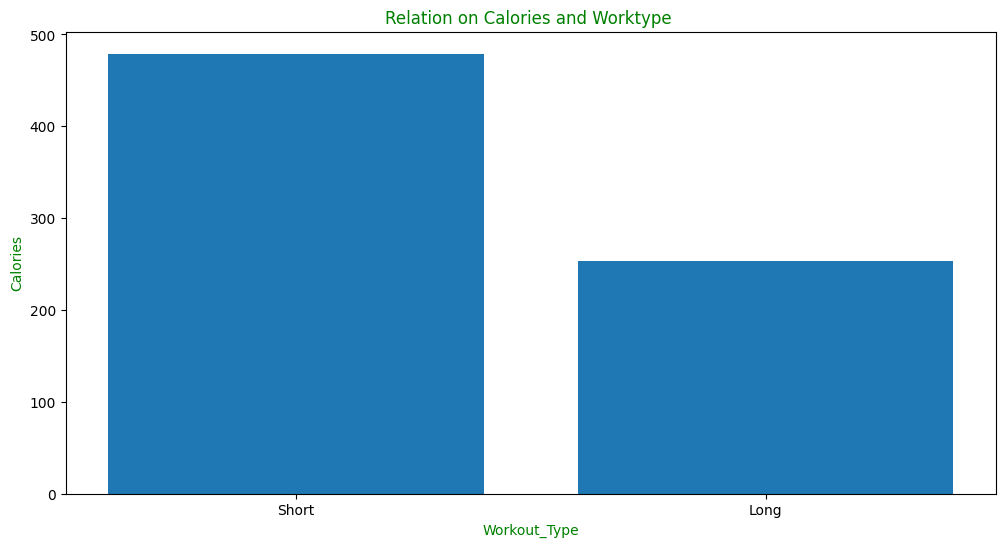

In [25]:
plt.figure(figsize=(12,6))
plt.bar(df["Workout_Type"],df["Calories"])
plt.xlabel("Workout_Type",color="Green")
plt.ylabel("Calories",color="Green")
plt.title("Relation on Calories and Worktype ",color="Green")
plt.show()